### 2. KI-Aufkommen und Gründungsdynamik

> **Hypothese H1: Mit vermehrtem Aufkommen bzw. vermehrter Nutzung von Künstlicher Intelligenz
in der Gesellschaft stieg die Anzahl an Startup-Gründungen pro Jahr in Deutschland.**

Grundlage der Prüfung von H1 ist eine Zeitreihe der jährlichen Startup-Gründungen in
Deutschland für den Zeitraum 2018–2025. Sie unterscheidet zwischen der Gesamtzahl der
Gründungen, die den jährlichen Startupdetector-Reports entnommen ist,¹ und dem Teilsegment
der KI-Startups, das auf den Erhebungen des appliedAI Institute for Europe beruht.² Der für
2026 vorliegende Wert umfasst ausschließlich das erste Quartal und wird aus dem
Volljahresvergleich ausgeschlossen. Für 2018 liegt keine Aufschlüsselung des KI-Segments vor,
weshalb die KI-bezogene Reihe erst 2019 einsetzt. Als gesellschaftliche Zäsur des
KI-Aufkommens wird die Veröffentlichung von ChatGPT Ende
2022 herangezogen, sodass die Jahre bis einschließlich 2022 die Vor-Durchbruchphase und die
Jahre ab 2023 die Nach-Durchbruchphase bilden.

In [17]:

# =============================================================
#  Technisches Setup und Datenimport
# =============================================================
# Stellt die Verbindung zur gemeinsamen PostgreSQL-Datenbank des HTW-Servers her.
#
# WICHTIG — Encoding-Problem:
# Der Server laeuft mit server_encoding = SQL_ASCII. Das bedeutet, die Datenbank
# speichert rohe Bytes ohne Kodierungsinformation. Die Texte (z. B. Bundeslaender
# mit Umlauten wie "Baden-Wuerttemberg") wurden als UTF-8 eingefuegt. Ohne explizite
# Angabe versucht der Treiber eine andere Interpretation und loest einen
# UnicodeDecodeError aus. Die Loesung: dem Client explizit UTF-8 vorgeben.

# --- Bibliotheken ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from getpass import getpass         # sichere Passworteingabe zur Laufzeit

# --- Einheitliches Erscheinungsbild der Plots ---
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# --- Verbindungsparameter ---
# Zugangsdaten werden aus Umgebungsvariablen gelesen und nicht im Code gespeichert.
import os
DB_HOST = os.getenv("DB_HOST", "<DB_HOST>")
DB_PORT = os.getenv("DB_PORT", "5432")
DB_NAME = os.getenv("DB_NAME", "<DB_NAME>")
DB_USER = os.getenv("DB_USER", "<DB_USER>")

# Passwort wird beim Ausfuehren abgefragt (nicht im Notebook gespeichert)
DB_PASSWORD = getpass("Passwort fuer die Datenbank eingeben: ")

# --- SQLAlchemy-Engine erstellen ---
connection_string = (
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

# >>> Hier wird das Encoding-Problem geloest:
# client_encoding="utf8" weist den Treiber an, die gespeicherten Bytes
# als UTF-8 zu interpretieren. Das verhindert den UnicodeDecodeError.
engine = create_engine(
    connection_string,
    connect_args={"client_encoding": "utf8"}
)

# --- Verbindung testen ---
try:
    with engine.connect() as conn:
        version = conn.execute(text("SELECT version();")).fetchone()
    print("Verbindung erfolgreich hergestellt.")
    print("PostgreSQL-Version:", version[0])
except Exception as e:
    print("Verbindung fehlgeschlagen:")
    print(e)

# --- Tabellennamen zentral konfigurieren ---
# Falls die Tabellen in der Datenbank anders heissen, hier (und nur hier) anpassen.
TABLES = {
    "statistik":     "startup_statistik",       # jaehrliche Gesamt- und KI-Startup-Zahlen
    "bundesland":    "startup_bundesland",       # Gruendungen je Bundesland und Jahr
    "ki_bundesland": "ki_startup_bundesland",   # KI-Startups je Bundesland (2025)
    "ki_stadt":      "ki_startup_stadt",        # KI-Startups je Stadt (2025)
}

Passwort fuer die Datenbank eingeben:  ········


Verbindung erfolgreich hergestellt.
PostgreSQL-Version: PostgreSQL 12.18 (Debian 12.18-1.pgdg110+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 10.2.1-6) 10.2.1 20210110, 64-bit


In [25]:
# Daten aus der Datenbank laden
df = pd.read_sql(f"SELECT * FROM {TABLES['statistik']}", engine)
df.columns = [c.strip().lstrip("\ufeff") for c in df.columns]

# Teiljahr kennzeichnen: 2026 = nur Q1 (nicht volljahresvergleichbar)
df["ist_volljahr"] = ~df["quelle"].str.contains("Q1", case=False, na=False)
df = df.sort_values("jahr").reset_index(drop=True)
df_voll = df[df["ist_volljahr"]].copy()

spalten = ["jahr", "anzahl_aller_startups", "anzahl_der_ki_startups",
           "ki_startups_anteil", "ist_volljahr"]

In [26]:
# Jaehrliche Wachstumsraten
df_voll["wachstum_gesamt_pct"] = df_voll["anzahl_aller_startups"].pct_change() * 100
df_voll["wachstum_ki_pct"]     = df_voll["anzahl_der_ki_startups"].pct_change() * 100

# Vor-/Nach-Durchbruch-Vergleich (Zaesur: ChatGPT Ende 2022 -> ab 2023)
DURCHBRUCH = 2023
vor  = df_voll[df_voll["jahr"] <  DURCHBRUCH]
nach = df_voll[df_voll["jahr"] >= DURCHBRUCH]

vergleich = pd.DataFrame({
    "Vor-Durchbruch (2018-2022)": [vor["anzahl_aller_startups"].mean(),
                                   vor["anzahl_der_ki_startups"].mean(),
                                   vor["ki_startups_anteil"].mean()],
    "Nach-Durchbruch (2023-2025)": [nach["anzahl_aller_startups"].mean(),
                                    nach["anzahl_der_ki_startups"].mean(),
                                    nach["ki_startups_anteil"].mean()],
}, index=["Startups gesamt (Mittel)", "KI-Startups (Mittel)", "KI-Anteil % (Mittel)"])
vergleich["Veraenderung (%)"] = (vergleich.iloc[:, 1] / vergleich.iloc[:, 0] - 1) * 100

# Trendstaerke: Korrelation Jahr <-> Kennzahl (Pearson r)
ki = df_voll.dropna(subset=["anzahl_der_ki_startups"])

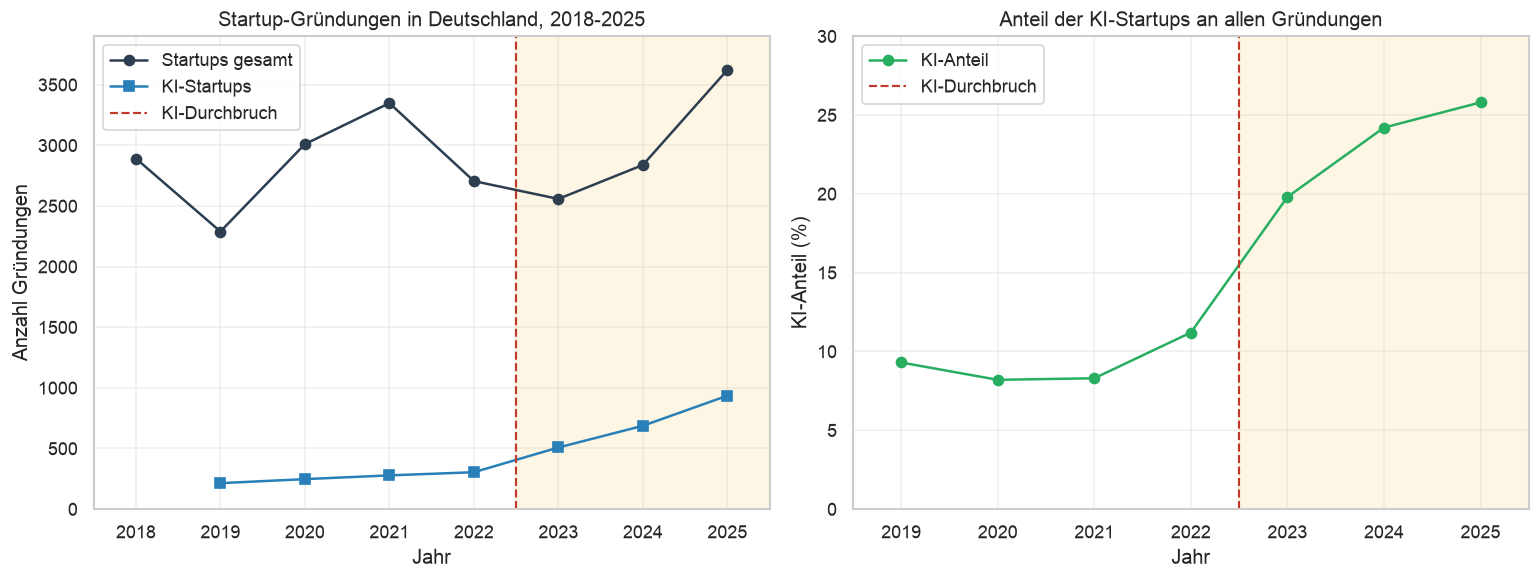

In [27]:
# ---- Abbildung 2.1: Gründungsdynamik und KI-Durchbruch ----
ki = df_voll.dropna(subset=["anzahl_der_ki_startups"])
DURCHBRUCH = 2022.5   # Zaesur: ChatGPT-Veröffentlichung Ende 2022

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: absolute Gründungszahlen
ax1.axvspan(DURCHBRUCH, 2025.5, color="#f2c94c", alpha=0.15)
ax1.plot(df_voll["jahr"], df_voll["anzahl_aller_startups"], "-o",
         color="#2c3e50", label="Startups gesamt")
ax1.plot(ki["jahr"], ki["anzahl_der_ki_startups"], "-s",
         color="#2980b9", label="KI-Startups")
ax1.axvline(DURCHBRUCH, color="#c0392b", ls="--", lw=1.3,
            label="KI-Durchbruch")
ax1.set_title("Startup-Gründungen in Deutschland, 2018-2025")
ax1.set_xlabel("Jahr"); ax1.set_ylabel("Anzahl Gründungen")
ax1.set_xlim(2017.5, 2025.5); ax1.set_ylim(0, 3900)
ax1.legend(loc="upper left"); ax1.grid(alpha=.3)

# Panel B: KI-Anteil
ax2.axvspan(DURCHBRUCH, 2025.5, color="#f2c94c", alpha=0.15)
ax2.plot(ki["jahr"], ki["ki_startups_anteil"], "-o", color="#27ae60", label="KI-Anteil")
ax2.axvline(DURCHBRUCH, color="#c0392b", ls="--", lw=1.3,
            label="KI-Durchbruch")
ax2.set_title("Anteil der KI-Startups an allen Gründungen")
ax2.set_xlabel("Jahr"); ax2.set_ylabel("KI-Anteil (%)")
ax2.set_xlim(2018.5, 2025.5); ax2.set_ylim(0, 30)
ax2.legend(loc="upper left"); ax2.grid(alpha=.3)

plt.tight_layout()
plt.savefig("abb_2_1_gruendungsdynamik.png", dpi=150, bbox_inches="tight")
plt.show()

<small><em>Abbildung 2.1: Gesamtzahl und KI-Startups (links), KI-Anteil an allen Gründungen (rechts)
<br>Quelle: jährliche Startupdetector-Reports, appliedAI Institute for Europe.</em></small>


**Diskussion**

Die Abbildung 2.1 macht ein deutlich differenziertes Bild sichtbar. Die
**Gesamtzahl der Gründungen** weist keinen stetigen Trend auf, sondern verläuft ausgeprägt
volatil: Die jährlichen Veränderungsraten schwanken zwischen −20,8 % (2019) und +31,5 % (2020),
und an der Zäsur Ende 2022 ist kein Strukturbruch erkennbar. Im ersten vollständigen Jahr nach
der Veröffentlichung von ChatGPT (2023) sinkt die Gesamtzahl sogar um 5,4 %. Entsprechend
besteht zwischen Kalenderjahr und Gesamtzahl nur ein schwacher linearer Zusammenhang
(Pearson r = 0,40), und der Mittelwert steigt von der Vor- zur Nach-Durchbruchphase lediglich
moderat von rund 2849 auf 3006 Gründungen (+5,5 %). 

Das **KI-Segment** entwickelt sich davon
grundlegend abweichend: Die Zahl der KI-Startups nimmt nahezu monoton zu von 214 (2019) auf
935 (2025) und korreliert stark mit der Zeit (r = 0,93), mit einem auffälligen Sprung von
+67,1 % zwischen 2022 und 2023. Parallel steigt der KI-Anteil an allen Gründungen von rund
8–9 % (bis 2021) nahezu linear auf 25,8 % (2025), im Mittelwert von 9,2 % auf 23,3 %. Der
KI-Durchbruch schlägt sich damit klar im KI-Segment nieder, nicht jedoch im Gesamtvolumen der
Gründungen.

**Schlussfolgerung**

H1 ist differenziert zu beantworten. In der strengen Lesart, die auf die
Anzahl *aller* Startup-Gründungen abstellt, wird die Hypothese durch die Daten nicht gestützt,
da das Gesamtvolumen keinen an der KI-Zäsur ansetzenden Anstieg zeigt. In einer auf KI-Startups
bezogenen Lesart wird sie hingegen klar bestätigt: Sowohl die absolute Zahl der KI-Startups als
auch deren Anteil am Gründungsgeschehen steigen im Untersuchungszeitraum deutlich und zeitlich
klar an der Zäsur an.

---
<small>¹ Startupdetector, jährliche Startup-Reports 2018–2025, startupdetector.de.<br>
² appliedAI Institute for Europe, „AI Startup Landscape" (Reportreihe 2019–2025), https://www.appliedai-institute.de/collections/startups/.</small>

### 3. Räumliche Verschiebung der Gründungsstandorte

> **Leitfrage H2: Wie haben sich die geografischen Standorte von Startup-Gründungen
in Deutschland im Zeitverlauf verändert?**

Die Untersuchung von H2 gliedert sich in zwei Teile: zunächst die Standortverteilung *aller*
Startup-Gründungen im Zeitverlauf, anschließend die räumliche Verteilung speziell der
KI-Startups. Beide Teile werden getrennt diskutiert und mit einer Zwischenschlussfolgerung
abgeschlossen.

In [28]:
# Bundesland-Daten aus der Datenbank laden
bl = pd.read_sql(f"SELECT * FROM {TABLES['bundesland']}", engine)
bl.columns = [c.strip().lstrip("\ufeff") for c in bl.columns]

# Analysefenster: Jahre mit vollständiger Länderabdeckung (2018 & 2026 leer)
jahressumme = bl.groupby("jahr")["anzahl_startups"].sum()
gueltige_jahre = jahressumme[jahressumme > 0].index
bl = bl[bl["jahr"].isin(gueltige_jahre)].copy()

# Länderanteil je Jahr (%)
bl["anteil_pct"] = bl["anzahl_startups"] / bl.groupby("jahr")["anzahl_startups"].transform("sum") * 100

# Kreuztabelle: Bundesländer (Zeilen) x Jahre (Spalten), sortiert nach Grösse 2025
pivot = bl.pivot(index="bundesland", columns="jahr", values="anzahl_startups")
pivot = pivot.sort_values(2025, ascending=False)

In [29]:
# ---- Konzentrationsmasse je Jahr ----
# Berlin-Anteil, CR4 (Summe der 4 grössten Laender), HHI (Herfindahl-Hirschman-Index)
rows = []
for j, g in bl.groupby("jahr"):
    s = g["anteil_pct"].sort_values(ascending=False)
    rows.append({"jahr": j,
                 "Berlin_Anteil": g.loc[g["bundesland"] == "Berlin", "anteil_pct"].iloc[0],
                 "CR4": s.head(4).sum(),
                 "HHI": (s ** 2).sum()})
konzentration = pd.DataFrame(rows).set_index("jahr").round(1)

# Rangfolge der drei fuehrenden Laender

for j in [2019, 2022, 2025]:
    top = bl[bl["jahr"] == j].sort_values("anzahl_startups", ascending=False)["bundesland"].tolist()

# Wachstum je Bundesland 2019 -> 2025 (mit absoluten Basiswerten)
p = bl.pivot(index="bundesland", columns="jahr", values="anzahl_startups")
wachstum = pd.DataFrame({
    "2019": p[2019].astype(int),
    "2025": p[2025].astype(int),
    "Wachstum_%": ((p[2025] / p[2019] - 1) * 100).round(1),
}).sort_values("Wachstum_%", ascending=False)
gesamt = (p[2025].sum() / p[2019].sum() - 1) * 100

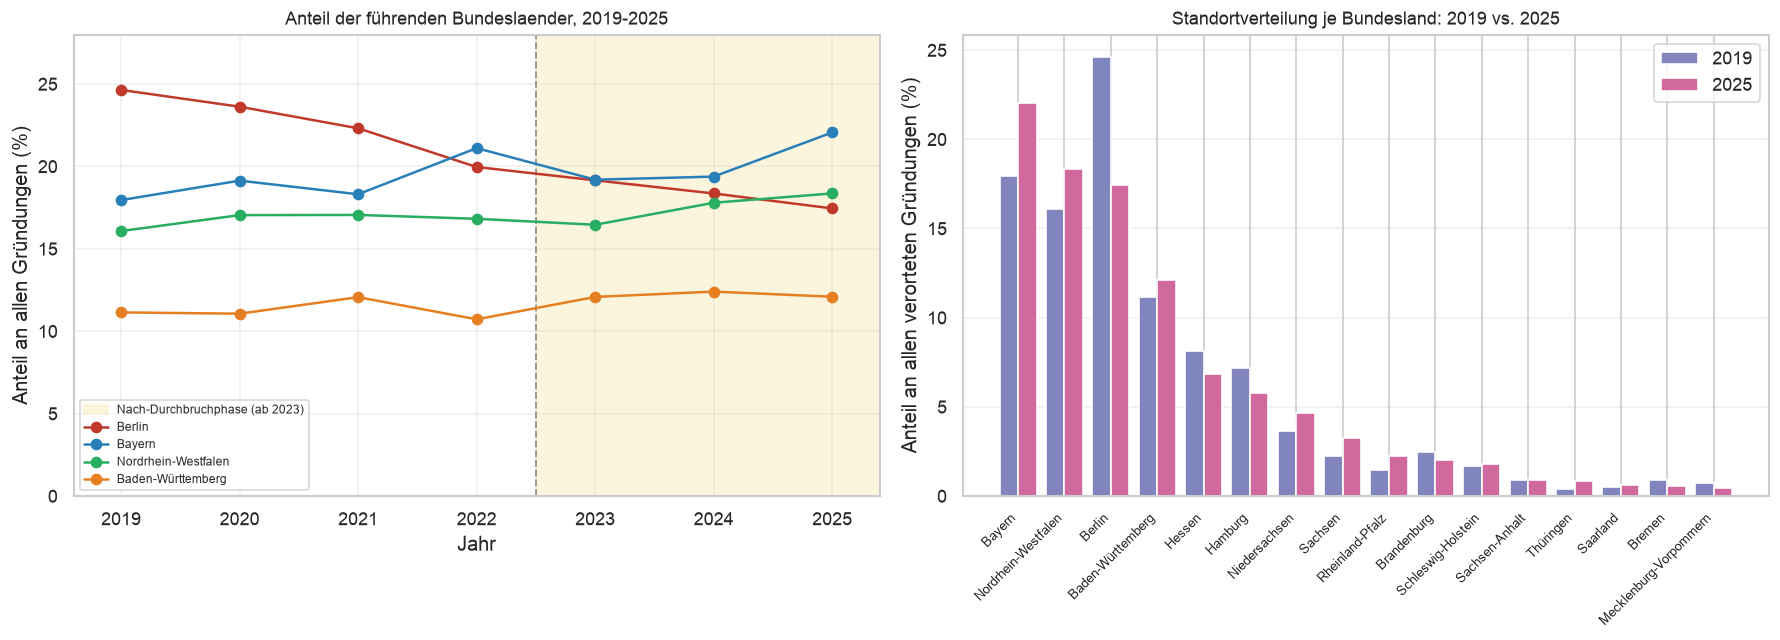

In [23]:
# ---- Abbildung 3.1: Anteil der führenden Bundesländer (links) und Standortverteilung 2019 vs. 2025 (rechts) ----
bl = pd.read_sql(f"SELECT * FROM {TABLES['bundesland']}", engine)
bl.columns = [c.strip().lstrip("\ufeff") for c in bl.columns]
js = bl.groupby("jahr")["anzahl_startups"].sum(); gj = js[js > 0].index
bl = bl[bl["jahr"].isin(gj)].copy()
bl["anteil"] = bl["anzahl_startups"] / bl.groupby("jahr")["anzahl_startups"].transform("sum") * 100
pa = bl.pivot(index="bundesland", columns="jahr", values="anteil")
jahre = sorted(gj)

top = ["Berlin", "Bayern", "Nordrhein-Westfalen", "Baden-Württemberg"]
if "Baden-Wuüttemberg" not in pa.index and "Baden-Württemberg" in pa.index:
    top = ["Berlin", "Bayern", "Nordrhein-Westfalen", "Baden-Württemberg"]
farben = {top[0]: "#c0392b", top[1]: "#2980b9", top[2]: "#27ae60", top[3]: "#e67e22"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Anteil der führenden Laender im Zeitverlauf
ax1.axvspan(2022.5, 2025.4, color="#f2c94c", alpha=0.18, label="Nach-Durchbruchphase (ab 2023)")
ax1.axvline(2022.5, color="#888888", ls="--", lw=1.1, alpha=.9)
for land in top:
    ax1.plot(jahre, pa.loc[land, jahre], "-o", color=farben[land], label=land)
ax1.set_title("Anteil der führenden Bundeslaender, 2019-2025", fontsize=11)
ax1.set_xlabel("Jahr"); ax1.set_ylabel("Anteil an allen Gründungen (%)")
ax1.set_xlim(2018.6, 2025.4); ax1.set_ylim(0, 28)
ax1.legend(loc="lower left", fontsize=7); ax1.grid(alpha=.3)

# Panel B: Standortverteilung 2019 vs. 2025
order = pa[2025].sort_values(ascending=False).index
x = np.arange(len(order)); w = 0.4
ax2.bar(x - w/2, pa.loc[order, 2019], width=w, color="#8085bd", label="2019")
ax2.bar(x + w/2, pa.loc[order, 2025], width=w, color="#d1699f", label="2025")
ax2.set_xticks(x); ax2.set_xticklabels(order, rotation=45, ha="right", fontsize=8)
ax2.set_ylabel("Anteil an allen verorteten Gründungen (%)")
ax2.set_title("Standortverteilung je Bundesland: 2019 vs. 2025", fontsize=11)
ax2.legend(loc="upper right"); ax2.grid(alpha=.3, axis="y")

plt.tight_layout()
plt.savefig("abb_4_2_standorte_gesamt.png", dpi=150, bbox_inches="tight")
plt.show()

<small><em>Abbildung 3.1: Anteil der führenden Bundesländer (links) und Standortverteilung 2019 vs. 2025 (rechts)<br>Quelle: Eigene Berechnung und Darstellung auf Basis der jährlichen Startupdetector-Reports.</em></small>

#### **3.1 Standorte aller Startup-Gründungen**

Datengrundlage ist eine nach den 16 Bundesländern aufgeschlüsselte Zeitreihe aller
Startup-Gründungen für den Zeitraum 2019–2025 aus den jährlichen Startupdetector-Reports.¹
Eine Konsistenzprüfung bestätigt, dass die Summe der Ländergründungen für jedes Jahr des
Analysefensters exakt der Gesamtzahl aus dem Hauptdatensatz entspricht.

**Diskussion**

Die Abbildung 3.1 zeichnet ein konsistentes Bild einer moderaten
räumlichen Dekonzentration. Der Anteil des größten Standorts, Berlin, sinkt kontinuierlich von
24,6 % (2019) auf 17,4 % (2025). Bemerkenswert ist dabei, dass diese Entwicklung nicht mit einer
breiten Streuung der Gründungstätigkeit in die Fläche einhergeht: Die Konzentrationsrate der
vier größten Länder verharrt bei rund 67–71 %, und der Herfindahl-Hirschman-Index sinkt
nur schwach von etwa 1460 auf 1400 – ein weiterhin moderates Konzentrationsniveau. Die
räumliche Struktur verschiebt sich somit weniger *in die Breite* als vielmehr *innerhalb der
führenden Länder*. Diese Umverteilung wird in der Rangfolge unmittelbar sichtbar: Berlin fällt
vom ersten Platz (2019) über Rang 2 – ab 2022 von Bayern überholt – auf Rang 3 (2025, nun auch
hinter Nordrhein-Westfalen). Ursächlich ist ein stark ungleiches Wachstum. Während die
Gründungszahl bundesweit um 58 % zunimmt, wächst Berlin mit lediglich +12 % weit
unterdurchschnittlich, wohingegen Bayern (+94 %), Nordrhein-Westfalen (+81 %) und
Baden-Württemberg (+72 %) überdurchschnittlich zulegen. Berlin verliert damit nicht absolut,
sondern *relativ* an Gewicht: Der Standort wächst langsamer als das übrige Bundesgebiet.
Plausible, aus den Daten allerdings nicht unmittelbar ableitbare Erklärungen wären eine
zunehmende Reife und Sättigung des Berliner Ökosystems sowie ein Aufholen wirtschaftsstarker
Flächenländer; diese Deutungen sind als Hypothesen zu verstehen und nicht als belegte
Kausalzusammenhänge.

**Schlussfolgerung**

Für die allgemeinen Gründungsstandorte lässt sich H2 klar beantworten: Die
geografische Verteilung hat sich im Untersuchungszeitraum spürbar verschoben – weg von der
vormals dominierenden Hauptstadt hin zu den großen Flächenländern des Südens und Westens. Die
Verschiebung ist eine *Umverteilung an der Spitze*, keine flächendeckende Streuung. Das
Gründungsgeschehen bleibt auf wenige starke Länder konzentriert, deren Rangfolge sich jedoch neu
ordnet.

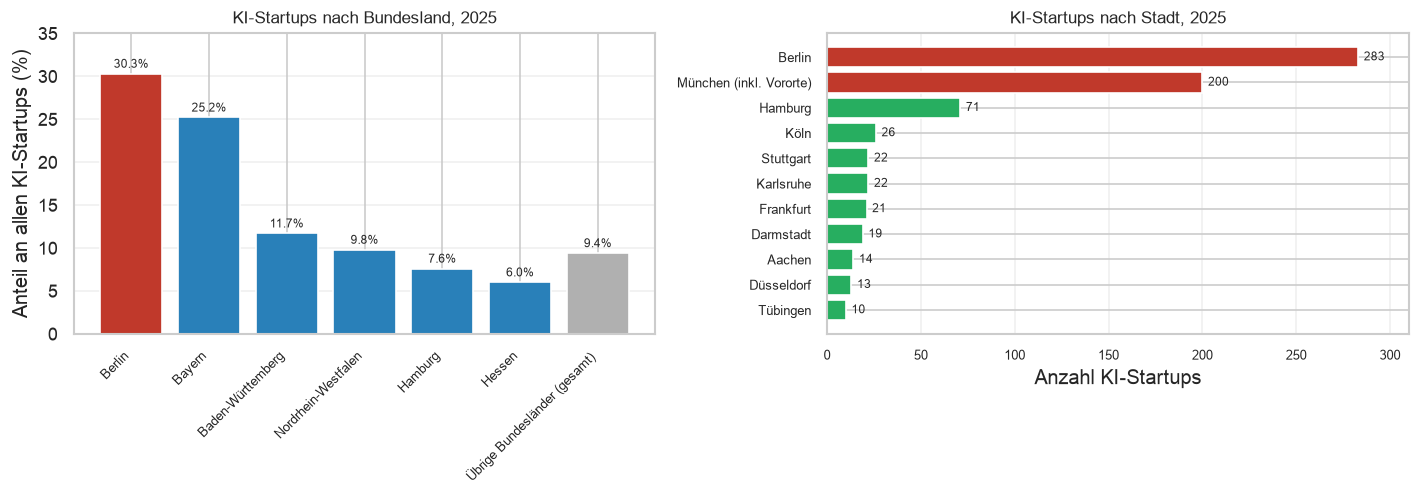

In [30]:
# ---- Abbildung 3.2: KI-Startups nach Bundesland (links) und Stadt (rechts) ----
blk = pd.read_sql(f"SELECT * FROM {TABLES['ki_bundesland']}", engine)
blk.columns = [c.strip().lstrip("\ufeff") for c in blk.columns]
st = pd.read_sql(f"SELECT * FROM {TABLES['ki_stadt']}", engine)
st.columns = [c.strip().lstrip("\ufeff") for c in st.columns]

# Bundesland: benannte Länder nach Anteil absteigend, "Übrige" ans Ende
mask_rest = blk["bundesland"].str.contains("brige")
plot = pd.concat([blk[~mask_rest].sort_values("anteil_prozent", ascending=False), blk[mask_rest]])
farben_bl = ["#c0392b" if b == "Berlin" else ("#b0b0b0" if "brige" in b else "#2980b9")
             for b in plot["bundesland"]]
xb = np.arange(len(plot))

# Stadt: nach Anzahl sortiert, Berlin + München hervorheben
sp = st.sort_values("anzahl")
farben_st = ["#c0392b" if s.startswith(("Berlin", "M")) else "#27ae60" for s in sp["stadt"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

# Panel A: Bundesland (vertikale Balken)
ax1.bar(xb, plot["anteil_prozent"], color=farben_bl)
for i, pp in enumerate(plot["anteil_prozent"]):
    ax1.text(i, pp + 0.4, f"{pp:.1f}%", ha="center", va="bottom", fontsize=7)
ax1.set_xticks(xb); ax1.set_xticklabels(plot["bundesland"], rotation=45, ha="right", fontsize=8)
ax1.set_ylabel("Anteil an allen KI-Startups (%)"); ax1.set_ylim(0, 35)
ax1.set_title("KI-Startups nach Bundesland, 2025", fontsize=10); ax1.grid(alpha=.3, axis="y")

# Panel B: Stadt (horizontale Balken)
ax2.barh(sp["stadt"], sp["anzahl"], color=farben_st)
for y, v in enumerate(sp["anzahl"]):
    ax2.text(v + 3, y, str(int(v)), va="center", fontsize=7)
ax2.set_xlabel("Anzahl KI-Startups"); ax2.set_xlim(0, 310)
ax2.set_title("KI-Startups nach Stadt, 2025", fontsize=10)
ax2.grid(alpha=.3, axis="x"); ax2.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig("abb_4_4_ki_verteilung.png", dpi=150, bbox_inches="tight")
plt.show()

<small><em>Abbildung 3.2: KI-Startups nach Bundesland (links) und Stadt (rechts)<br>Quelle: Eigene Darstellung auf Basis von appliedAI Institute for Europe, „German AI Startup Landscape 2025".</em></small>

#### **3.2 Standorte der KI-Startups**

Für die KI-spezifische Betrachtung dient ein Querschnitt der KI-Startups des Jahres 2025 auf
Bundesland- und Städteebene aus dem appliedAI-Report als Datengrundlage.² Anders als bei den
allgemeinen Standorten liegt hier keine durchgehende Zeitreihe vor; die Auswertung ist daher als
Momentaufnahme des aktuellen Rands zu verstehen und wird bewusst getrennt von der
Zeitreihenanalyse geführt.

**Diskussion**

Die Abbildung 3.2 zeigt eine ausgeprägte räumliche Konzentration der
KI-Startups. Auf Bundesland-Ebene dominiert Berlin mit 30,3 % (~283 KI-Startups) vor Bayern mit
25,2 % (~236); mit deutlichem Abstand folgen Baden-Württemberg (11,7 %), Nordrhein-Westfalen
(9,8 %), Hamburg (7,6 %) und Hessen (6,0 %). Diese sechs Länder vereinen über 90 % aller
KI-Startups, während auf die übrigen zehn Länder zusammen nur 9,4 % (~88) entfallen. Auf
Städte-Ebene verschärft sich das Bild zusätzlich: Berlin (283) und München (200) stellen
gemeinsam rund die Hälfte aller KI-Startups, gefolgt von Hamburg (71); danach fällt die
Verteilung steil ab (Köln 26, Karlsruhe und Stuttgart je 22). Besonders aufschlussreich wird
dieser Befund im **Vergleich mit den allgemeinen Standorten** (Abschnitt 3.1). Dort verliert
Berlin an Anteil und fällt bis 2025 auf Rang 3 zurück; im KI-Segment hingegen ist Berlin mit
30,3 % klar führend und beheimatet fast ein Drittel aller KI-Gründungen – nahezu das Doppelte
seines Anteils an allen Gründungen (17,4 %). KI-Gründungen sind damit räumlich deutlich stärker
konzentriert als das Gründungsgeschehen insgesamt, und diese Konzentration bündelt sich gerade in
jenem Standort, der im Gesamtbild an Gewicht verliert.

**Schlussfolgerung**

Die räumliche Verteilung der KI-Startups folgt einem eigenen Muster, das
sich von der allgemeinen Dekonzentration abhebt: Während sich die Gründungstätigkeit insgesamt
stärker über die großen Flächenländer verteilt, konzentriert sich die KI-Gründungstätigkeit
weiterhin auf wenige Metropolen, allen voran Berlin und München. Bezogen auf die Leitfrage H2
bedeutet dies, dass sich *geografische Verschiebung* je nach Segment gegenläufig darstellt –
Dekonzentration im Gesamtgeschehen, anhaltende Metropolkonzentration bei KI.

Insgesamt beantwortet sich H2 damit segmentabhängig: Das allgemeine Gründungsgeschehen
dekonzentriert sich zugunsten der großen Flächenländer, während die KI-Gründungen ihre
Metropolkonzentration auf Berlin und München beibehalten.

---
<small>¹ Startupdetector, jährliche Startup-Reports 2019–2025, startupdetector.de.</small>

<small>² appliedAI Institute for Europe, „German AI Startup Landscape 2025," https://www.appliedai-institute.de/en/publications/ai-startup-landscape-2025/.</small>